In [10]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [12]:
class CNN1DClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self,
                 num_filters=[32, 64],
                 kernel_sizes=[3, 3],
                 dropout=0.2,
                 fc_hidden_layers=(32,),
                 input_size=None,
                 output_size=8,
                 solver='adam',  # ← ADICIONADO (igual LSTM)
                 learning_rate=0.001,
                 momentum=0.9,    # ← ADICIONADO (igual LSTM)
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.num_filters = num_filters
        self.kernel_sizes = kernel_sizes
        self.dropout = dropout
        self.fc_hidden_layers = fc_hidden_layers
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver                    # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum                # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class CNN1DModel(nn.Module):
            def __init__(self, input_size, num_filters, kernel_sizes, dropout,
                         fc_hiddens, output_size):
                super(CNN1DModel, self).__init__()

                # Camadas Convolucionais 1D
                conv_layers = []
                prev_channels = 1

                for i, (filters, kernel) in enumerate(zip(num_filters, kernel_sizes)):
                    conv_layers.append(
                        nn.Conv1d(in_channels=prev_channels,
                                 out_channels=filters,
                                 kernel_size=kernel,
                                 padding='same')
                    )
                    conv_layers.append(nn.BatchNorm1d(filters))
                    conv_layers.append(nn.ReLU())
                    conv_layers.append(nn.MaxPool1d(kernel_size=2))
                    conv_layers.append(nn.Dropout(dropout))
                    prev_channels = filters

                self.conv_layers = nn.Sequential(*conv_layers)

                # Calcular tamanho após convoluções
                conv_out_size = self._get_conv_output_size(input_size)

                # Fully connected layers
                fc_layers = []
                prev_size = conv_out_size

                for hidden_size in fc_hiddens:
                    fc_layers.append(nn.Linear(prev_size, hidden_size))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(dropout))
                    prev_size = hidden_size

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc_layers = nn.Sequential(*fc_layers)

            def _get_conv_output_size(self, input_size):
                with torch.no_grad():
                    x = torch.zeros(1, 1, input_size)
                    x = self.conv_layers(x)
                    return x.view(1, -1).size(1)

            def forward(self, x):
                # x shape: (batch, features) → (batch, 1, features)
                x = x.unsqueeze(1)
                x = self.conv_layers(x)
                x = x.view(x.size(0), -1)
                x = self.fc_layers(x)
                return x

        return CNN1DModel(
            input_size=self.input_size,
            num_filters=self.num_filters,
            kernel_sizes=self.kernel_sizes,
            dropout=self.dropout,
            fc_hiddens=self.fc_hidden_layers,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        # CNN espera (batch, features) - o unsqueeze(1) é feito no forward
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
                #print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'num_filters': self.num_filters,
            'kernel_sizes': self.kernel_sizes,
            'dropout': self.dropout,
            'fc_hidden_layers': self.fc_hidden_layers,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_479/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_rmsprop
------------------------------
TRAIN
Accuracy: 0.8102
Precision: 0.8518
Recall: 0.8102
F1: 0.8112
Kappa: 0.7684
Error Rate: 0.1898

TEST
Accuracy: 0.1437
Precision: 0.2931
Recall: 0.1437
F1: 0.0719
Kappa: 0.0193
Error Rate: 0.8563
Gap (overfitting): 0.6666

CV
Mean: 0.8112
Std: 0.0912
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



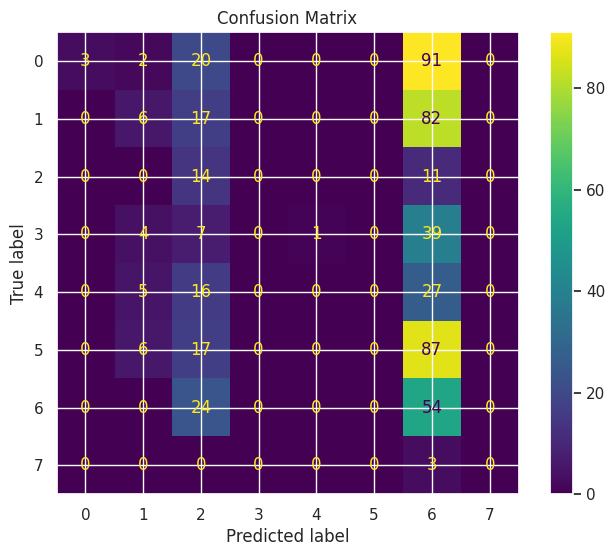

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_adam
------------------------------
TRAIN
Accuracy: 0.8703
Precision: 0.8746
Recall: 0.8703
F1: 0.8702
Kappa: 0.8427
Error Rate: 0.1297

TEST
Accuracy: 0.1437
Precision: 0.3255
Recall: 0.1437
F1: 0.0726
Kappa: 0.0204
Error Rate: 0.8563
Gap (overfitting): 0.7266

CV
Mean: 0.8218
Std: 0.0944
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



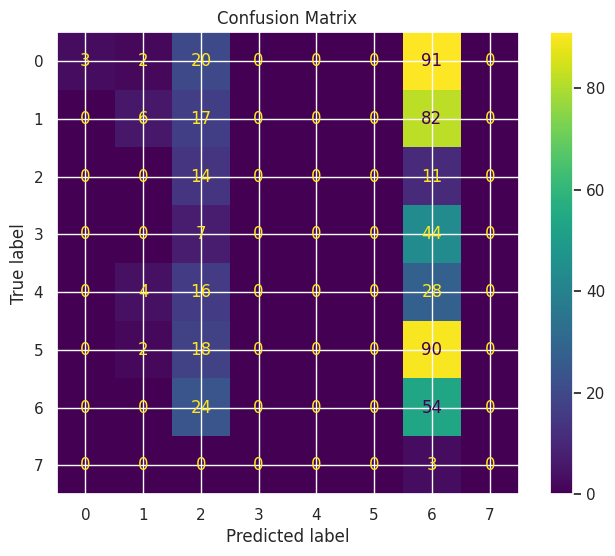

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.8431
Precision: 0.8525
Recall: 0.8431
F1: 0.8413
Kappa: 0.8091
Error Rate: 0.1569

TEST
Accuracy: 0.1269
Precision: 0.1076
Recall: 0.1269
F1: 0.0557
Kappa: 0.0030
Error Rate: 0.8731
Gap (overfitting): 0.7162

CV
Mean: 0.7888
Std: 0.0953
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



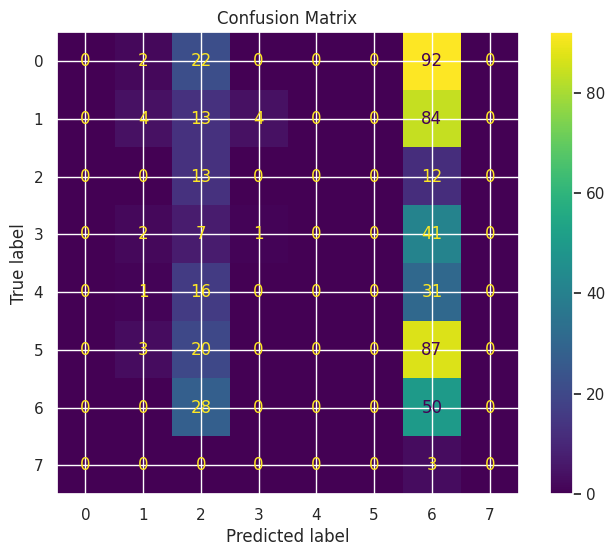

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.6749
Precision: 0.6926
Recall: 0.6749
F1: 0.6721
Kappa: 0.6025
Error Rate: 0.3251

TEST
Accuracy: 0.1399
Precision: 0.2009
Recall: 0.1399
F1: 0.1172
Kappa: 0.0374
Error Rate: 0.8601
Gap (overfitting): 0.5350

CV
Mean: 0.6723
Std: 0.0528
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



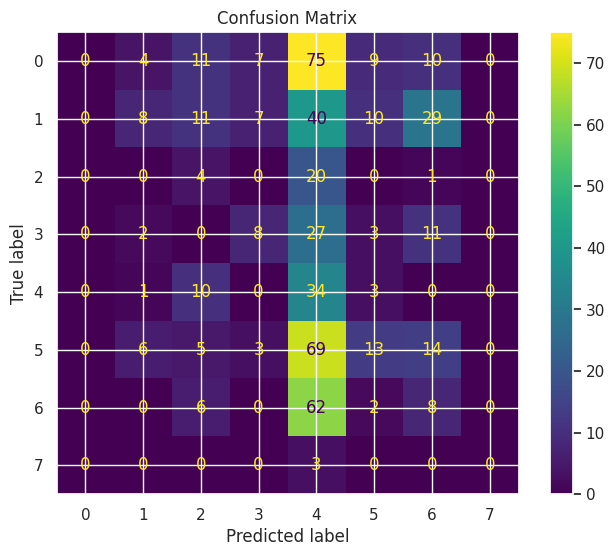

In [15]:
models_cnn = {}

# Base: comparar solvers
models_cnn['CNN_rmsprop'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn['CNN_adam'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn['CNN_sgd_momentum'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn['CNN_adam_lowLR'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_cnn, "cnn_experiments")

/tmp/ipykernel_479/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_sgd_momentum_30
------------------------------
TRAIN
Accuracy: 0.7294
Precision: 0.7540
Recall: 0.7294
F1: 0.7260
Kappa: 0.6722
Error Rate: 0.2706

TEST
Accuracy: 0.1549
Precision: 0.1232
Recall: 0.1549
F1: 0.1038
Kappa: 0.0281
Error Rate: 0.8451
Gap (overfitting): 0.5745

CV
Mean: 0.6706
Std: 0.0805
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



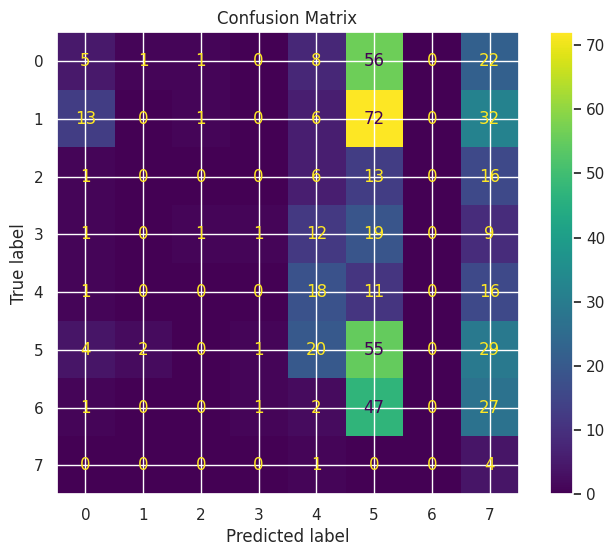

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_sgd_momentum_50
------------------------------
TRAIN
Accuracy: 0.7294
Precision: 0.7540
Recall: 0.7294
F1: 0.7260
Kappa: 0.6722
Error Rate: 0.2706

TEST
Accuracy: 0.1549
Precision: 0.1232
Recall: 0.1549
F1: 0.1038
Kappa: 0.0281
Error Rate: 0.8451
Gap (overfitting): 0.5745

CV
Mean: 0.6706
Std: 0.0805
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



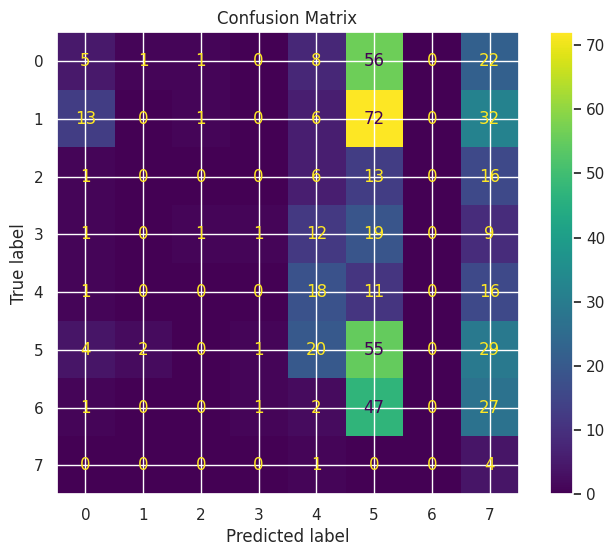

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_sgd_momentum_50_25
------------------------------
TRAIN
Accuracy: 0.9784
Precision: 0.9804
Recall: 0.9784
F1: 0.9786
Kappa: 0.9740
Error Rate: 0.0216

TEST
Accuracy: 0.1810
Precision: 0.1446
Recall: 0.1810
F1: 0.1037
Kappa: 0.0018
Error Rate: 0.8190
Gap (overfitting): 0.7974

CV
Mean: 0.8370
Std: 0.1602
------------------------------
Model params:
{'num_filters': [8, 16], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



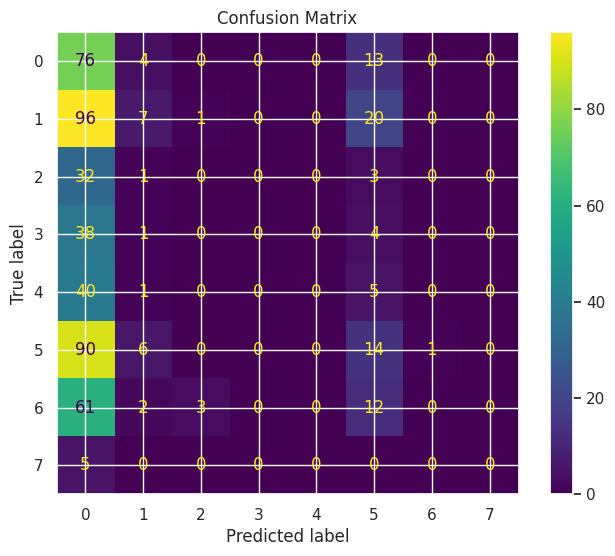

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_sgd_momentum_reg1e3
------------------------------
TRAIN
Accuracy: 0.6229
Precision: 0.6614
Recall: 0.6229
F1: 0.6238
Kappa: 0.5407
Error Rate: 0.3771

TEST
Accuracy: 0.1698
Precision: 0.2079
Recall: 0.1698
F1: 0.1187
Kappa: 0.0528
Error Rate: 0.8302
Gap (overfitting): 0.4531

CV
Mean: 0.6006
Std: 0.0498
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



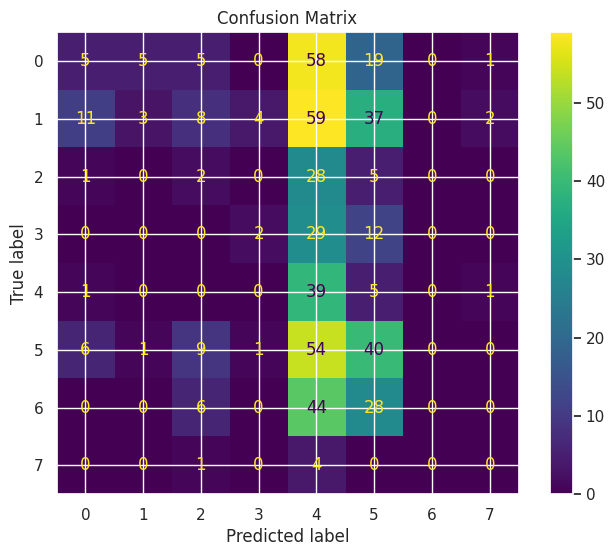

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_sgd_momentum_reg5e3
------------------------------
TRAIN
Accuracy: 0.5837
Precision: 0.6174
Recall: 0.5837
F1: 0.5809
Kappa: 0.4904
Error Rate: 0.4163

TEST
Accuracy: 0.1269
Precision: 0.2434
Recall: 0.1269
F1: 0.0847
Kappa: 0.0270
Error Rate: 0.8731
Gap (overfitting): 0.4568

CV
Mean: 0.5709
Std: 0.0536
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.5, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



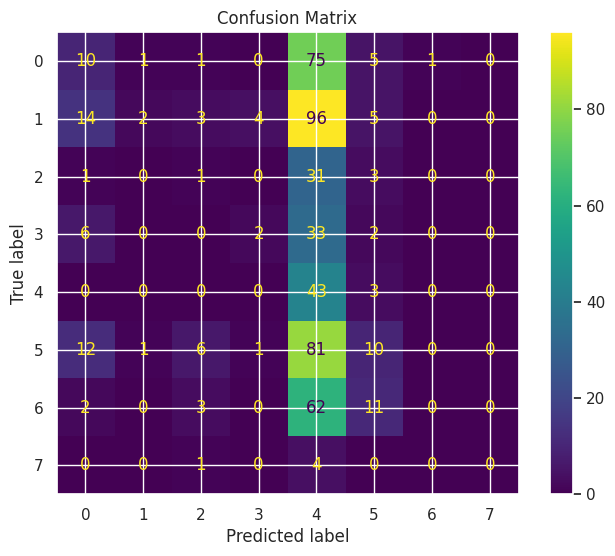


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_rmsprop_30
------------------------------
TRAIN
Accuracy: 0.7158
Precision: 0.7836
Recall: 0.7158
F1: 0.7133
Kappa: 0.6596
Error Rate: 0.2842

TEST
Accuracy: 0.2146
Precision: 0.4248
Recall: 0.2146
F1: 0.1385
Kappa: 0.0617
Error Rate: 0.7854
Gap (overfitting): 0.5012

CV
Mean: 0.7081
Std: 0.1124
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



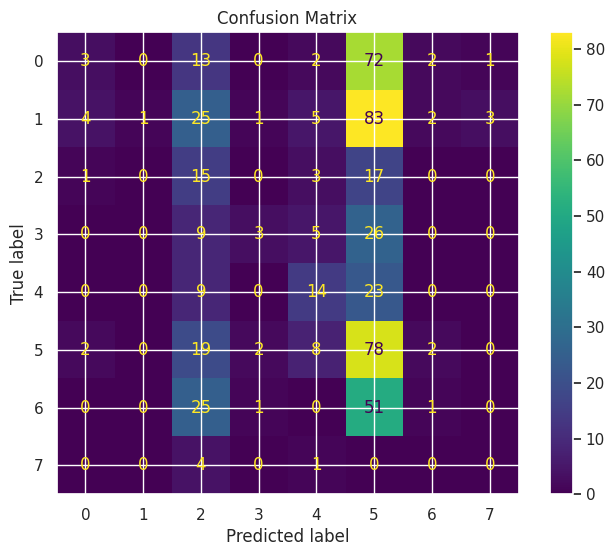

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_rmsprop_50
------------------------------
TRAIN
Accuracy: 0.8247
Precision: 0.8475
Recall: 0.8247
F1: 0.8230
Kappa: 0.7877
Error Rate: 0.1753

TEST
Accuracy: 0.1549
Precision: 0.3717
Recall: 0.1549
F1: 0.0983
Kappa: -0.0334
Error Rate: 0.8451
Gap (overfitting): 0.6698

CV
Mean: 0.7933
Std: 0.1159
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



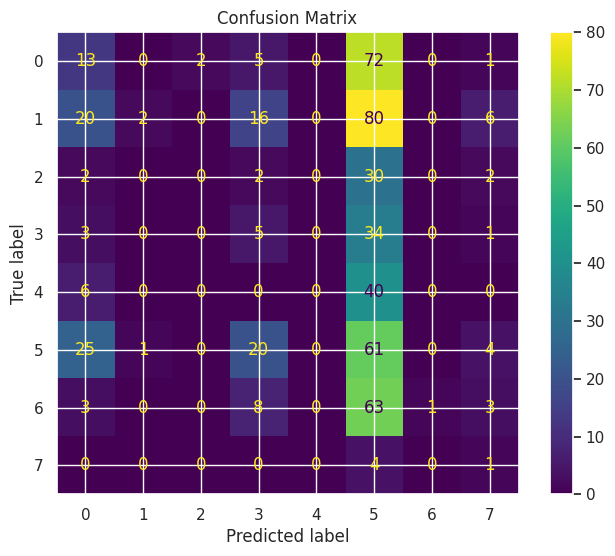

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_rmsprop_50_25
------------------------------
TRAIN
Accuracy: 0.8030
Precision: 0.8792
Recall: 0.8030
F1: 0.8114
Kappa: 0.7627
Error Rate: 0.1970

TEST
Accuracy: 0.1847
Precision: 0.1096
Recall: 0.1847
F1: 0.1037
Kappa: -0.0036
Error Rate: 0.8153
Gap (overfitting): 0.6183

CV
Mean: 0.8314
Std: 0.1565
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



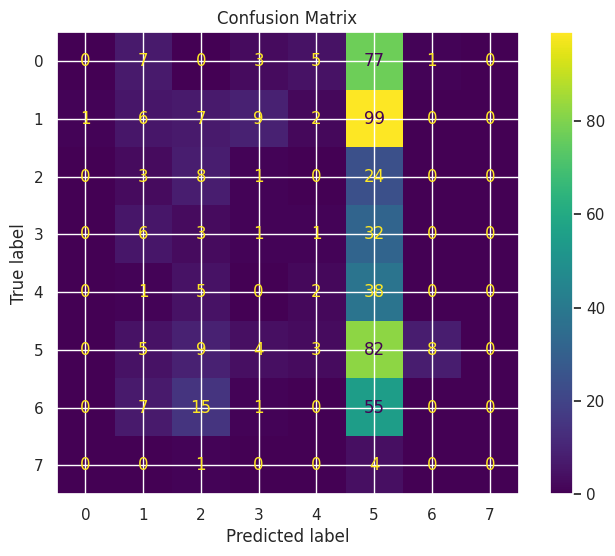

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_rmsprop_reg1e3
------------------------------
TRAIN
Accuracy: 0.7238
Precision: 0.7535
Recall: 0.7238
F1: 0.7235
Kappa: 0.6623
Error Rate: 0.2762

TEST
Accuracy: 0.2090
Precision: 0.2840
Recall: 0.2090
F1: 0.1170
Kappa: 0.0105
Error Rate: 0.7910
Gap (overfitting): 0.5148

CV
Mean: 0.6700
Std: 0.0605
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



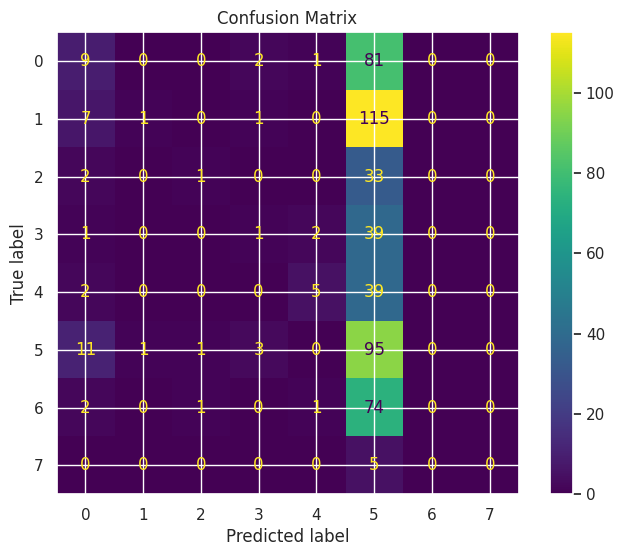

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_adam_lowLR_30
------------------------------
TRAIN
Accuracy: 0.6301
Precision: 0.6488
Recall: 0.6301
F1: 0.6287
Kappa: 0.5499
Error Rate: 0.3699

TEST
Accuracy: 0.1922
Precision: 0.1958
Recall: 0.1922
F1: 0.1174
Kappa: 0.0727
Error Rate: 0.8078
Gap (overfitting): 0.4379

CV
Mean: 0.6039
Std: 0.0628
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



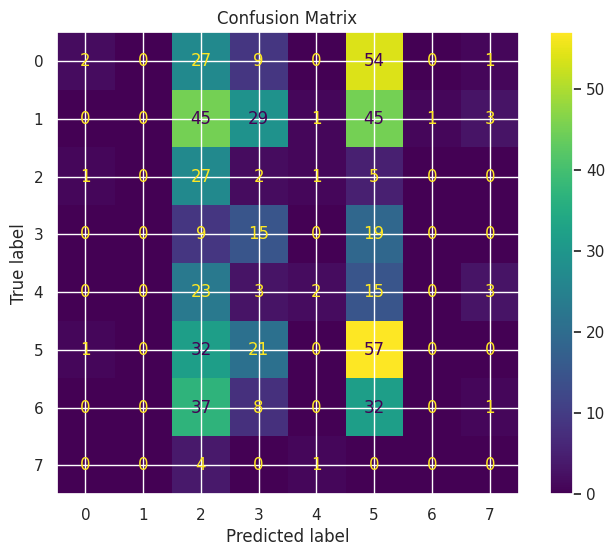

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_adam_lowLR_50
------------------------------
TRAIN
Accuracy: 0.6301
Precision: 0.6488
Recall: 0.6301
F1: 0.6287
Kappa: 0.5499
Error Rate: 0.3699

TEST
Accuracy: 0.1922
Precision: 0.1958
Recall: 0.1922
F1: 0.1174
Kappa: 0.0727
Error Rate: 0.8078
Gap (overfitting): 0.4379

CV
Mean: 0.6039
Std: 0.0628
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



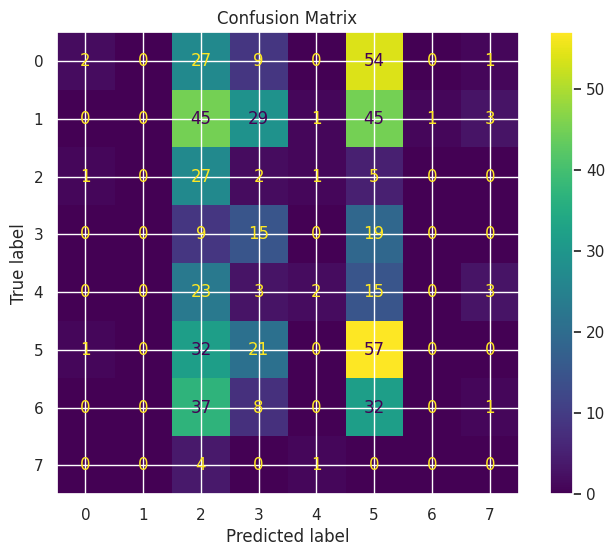

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_adam_lowLR_50_25
------------------------------
TRAIN
Accuracy: 0.8038
Precision: 0.8164
Recall: 0.8038
F1: 0.8040
Kappa: 0.7610
Error Rate: 0.1962

TEST
Accuracy: 0.2146
Precision: 0.2500
Recall: 0.2146
F1: 0.1097
Kappa: 0.0161
Error Rate: 0.7854
Gap (overfitting): 0.5893

CV
Mean: 0.7737
Std: 0.1306
------------------------------
Model params:
{'num_filters': [8, 16], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



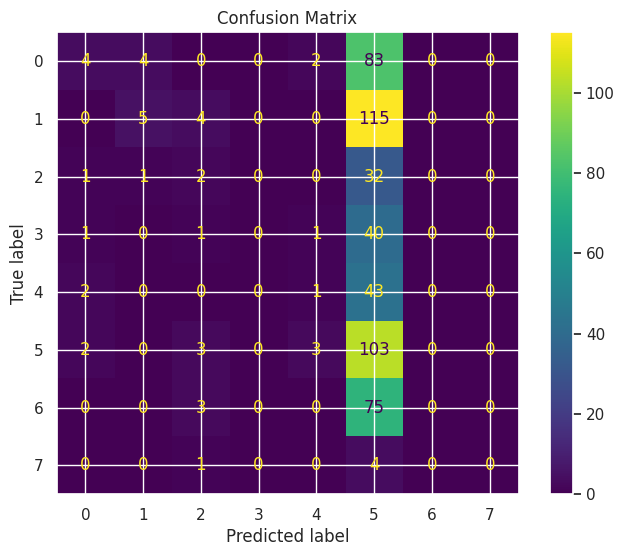

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_adam_lowLR_reg1e3
------------------------------
TRAIN
Accuracy: 0.6037
Precision: 0.6266
Recall: 0.6037
F1: 0.6033
Kappa: 0.5167
Error Rate: 0.3963

TEST
Accuracy: 0.1884
Precision: 0.1561
Recall: 0.1884
F1: 0.1255
Kappa: 0.0639
Error Rate: 0.8116
Gap (overfitting): 0.4153

CV
Mean: 0.6095
Std: 0.0578
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



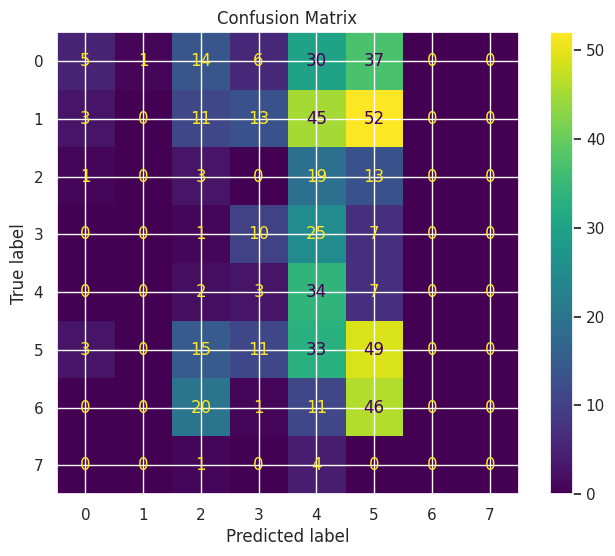

In [16]:
models_cnn_f1 = {}

# ============================================================
# 1º MELHOR: CNN_sgd_momentum
# Expansões: filtros, camadas, regularização
# ============================================================

models_cnn_f1['CNN_sgd_momentum_30'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_sgd_momentum_50'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

# 2 camadas convolucionais: [50, 25]
models_cnn_f1['CNN_sgd_momentum_50_25'] = CNN1DClassifier(
    num_filters=[8, 16], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

# Regularização (dropout)
models_cnn_f1['CNN_sgd_momentum_reg1e3'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_sgd_momentum_reg5e3'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.5, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 2º MELHOR: CNN_rmsprop
# ============================================================

models_cnn_f1['CNN_rmsprop_30'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_rmsprop_50'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_rmsprop_50_25'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_rmsprop_reg1e3'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.3, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 3º MELHOR: CNN_adam_lowLR
# ============================================================

models_cnn_f1['CNN_adam_lowLR_30'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_adam_lowLR_50'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_adam_lowLR_50_25'] = CNN1DClassifier(
    num_filters=[8,16], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f1['CNN_adam_lowLR_reg1e3'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.3, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_cnn_f1, "cnn_fase_1")

/tmp/ipykernel_479/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_solver_adam
------------------------------
TRAIN
Accuracy: 0.6413
Precision: 0.6622
Recall: 0.6413
F1: 0.6403
Kappa: 0.5587
Error Rate: 0.3587

TEST
Accuracy: 0.1287
Precision: 0.2593
Recall: 0.1287
F1: 0.1006
Kappa: 0.0264
Error Rate: 0.8713
Gap (overfitting): 0.5126

CV
Mean: 0.6196
Std: 0.0719
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



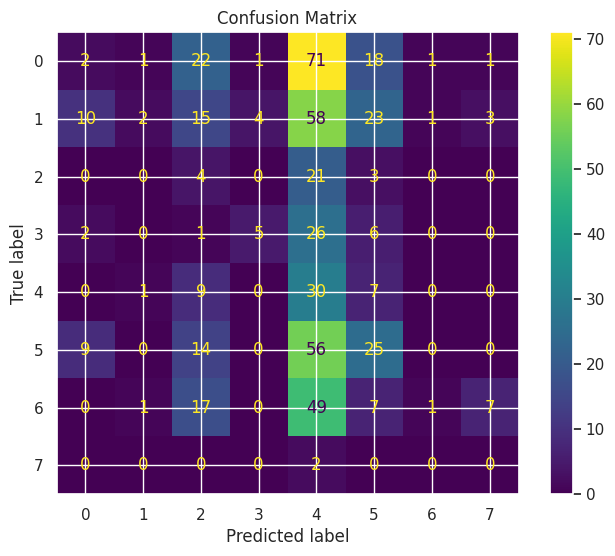

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_solver_sgd
------------------------------
TRAIN
Accuracy: 0.7358
Precision: 0.7821
Recall: 0.7358
F1: 0.7383
Kappa: 0.6815
Error Rate: 0.2642

TEST
Accuracy: 0.1231
Precision: 0.0919
Recall: 0.1231
F1: 0.0834
Kappa: 0.0043
Error Rate: 0.8769
Gap (overfitting): 0.6127

CV
Mean: 0.7384
Std: 0.0858
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



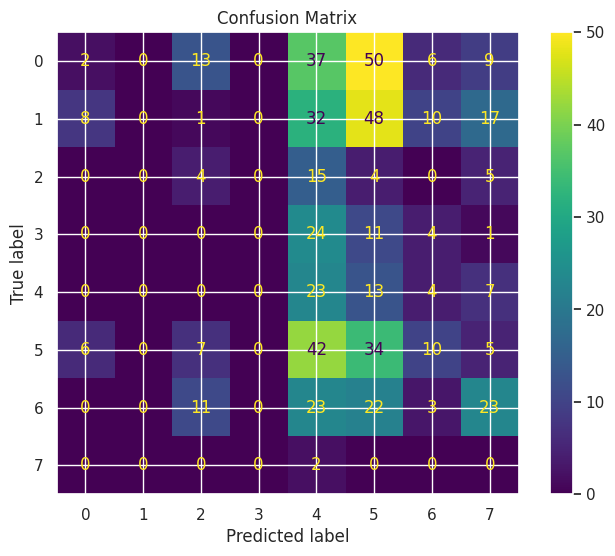

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_solver_rmsprop
------------------------------
TRAIN
Accuracy: 0.7094
Precision: 0.8004
Recall: 0.7094
F1: 0.7117
Kappa: 0.6516
Error Rate: 0.2906

TEST
Accuracy: 0.1399
Precision: 0.2525
Recall: 0.1399
F1: 0.1086
Kappa: 0.0372
Error Rate: 0.8601
Gap (overfitting): 0.5694

CV
Mean: 0.7697
Std: 0.0960
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



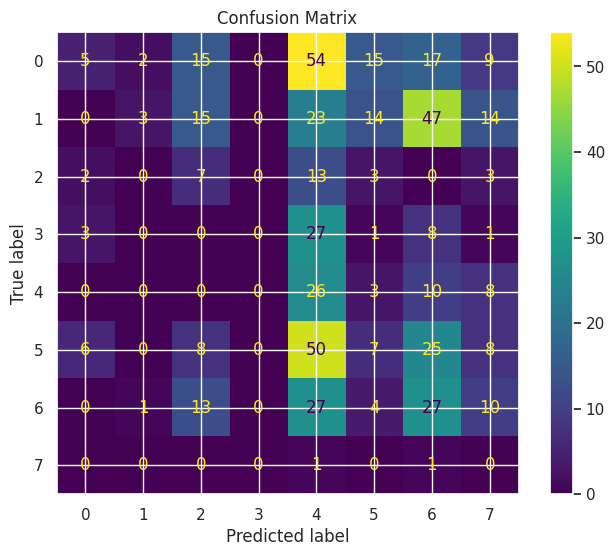


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_arch_30
------------------------------
TRAIN
Accuracy: 0.6413
Precision: 0.6622
Recall: 0.6413
F1: 0.6403
Kappa: 0.5587
Error Rate: 0.3587

TEST
Accuracy: 0.1287
Precision: 0.2593
Recall: 0.1287
F1: 0.1006
Kappa: 0.0264
Error Rate: 0.8713
Gap (overfitting): 0.5126

CV
Mean: 0.6196
Std: 0.0719
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



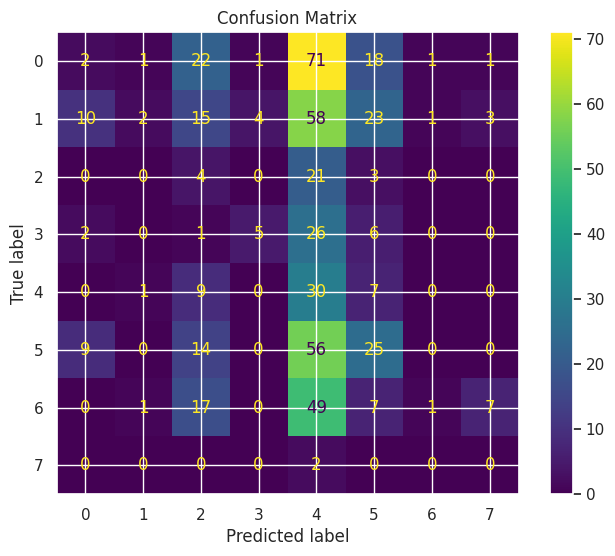


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_arch_50
------------------------------
TRAIN
Accuracy: 0.6693
Precision: 0.6824
Recall: 0.6693
F1: 0.6683
Kappa: 0.5934
Error Rate: 0.3307

TEST
Accuracy: 0.1269
Precision: 0.3400
Recall: 0.1269
F1: 0.0942
Kappa: 0.0186
Error Rate: 0.8731
Gap (overfitting): 0.5425

CV
Mean: 0.6583
Std: 0.0799
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



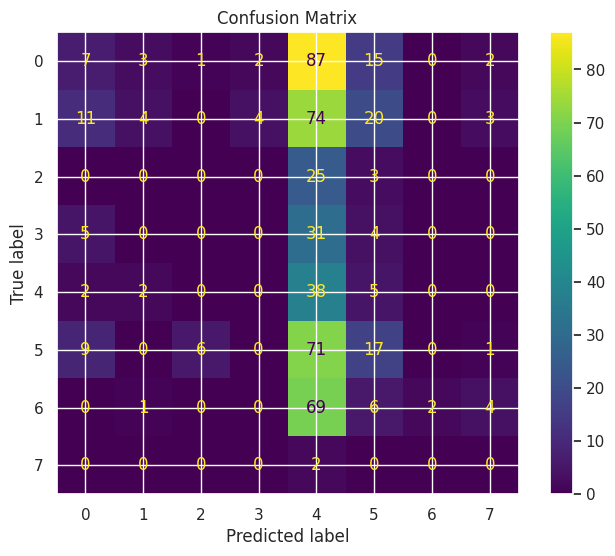

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_arch_50_25
------------------------------
TRAIN
Accuracy: 0.8423
Precision: 0.8447
Recall: 0.8423
F1: 0.8377
Kappa: 0.8064
Error Rate: 0.1577

TEST
Accuracy: 0.1660
Precision: 0.0539
Recall: 0.1660
F1: 0.0760
Kappa: -0.0055
Error Rate: 0.8340
Gap (overfitting): 0.6762

CV
Mean: 0.7950
Std: 0.1500
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



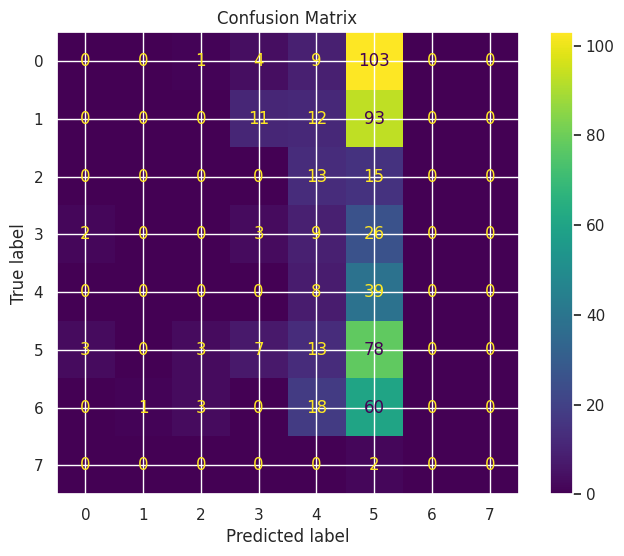


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_dropout_0
------------------------------
TRAIN
Accuracy: 0.6413
Precision: 0.6622
Recall: 0.6413
F1: 0.6403
Kappa: 0.5587
Error Rate: 0.3587

TEST
Accuracy: 0.1287
Precision: 0.2593
Recall: 0.1287
F1: 0.1006
Kappa: 0.0264
Error Rate: 0.8713
Gap (overfitting): 0.5126

CV
Mean: 0.6196
Std: 0.0719
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



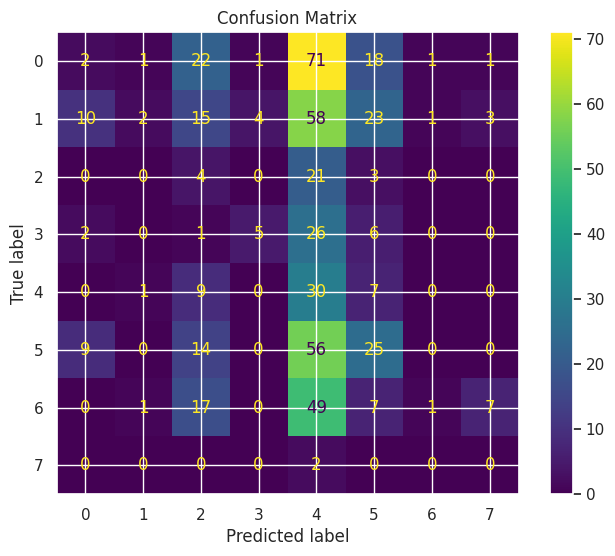


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_dropout_1e-1
------------------------------
TRAIN
Accuracy: 0.6181
Precision: 0.6514
Recall: 0.6181
F1: 0.6130
Kappa: 0.5276
Error Rate: 0.3819

TEST
Accuracy: 0.1138
Precision: 0.3734
Recall: 0.1138
F1: 0.1006
Kappa: 0.0286
Error Rate: 0.8862
Gap (overfitting): 0.5043

CV
Mean: 0.6112
Std: 0.0671
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.1, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



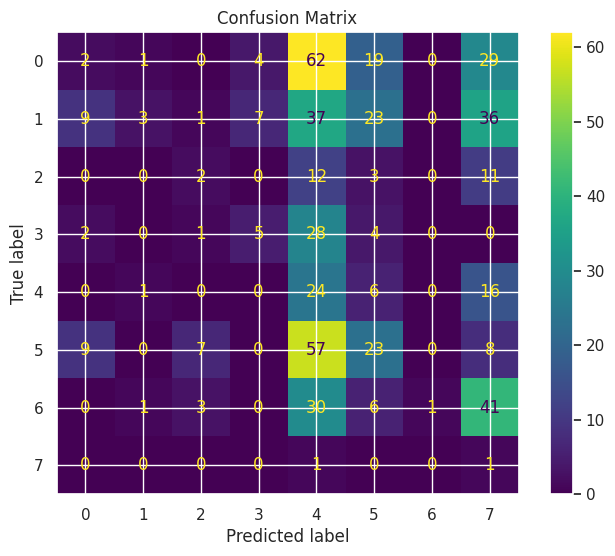


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_dropout_1e-1.5
------------------------------
TRAIN
Accuracy: 0.5877
Precision: 0.6340
Recall: 0.5877
F1: 0.5791
Kappa: 0.4883
Error Rate: 0.4123

TEST
Accuracy: 0.1045
Precision: 0.3595
Recall: 0.1045
F1: 0.0806
Kappa: 0.0066
Error Rate: 0.8955
Gap (overfitting): 0.4832

CV
Mean: 0.5821
Std: 0.0730
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



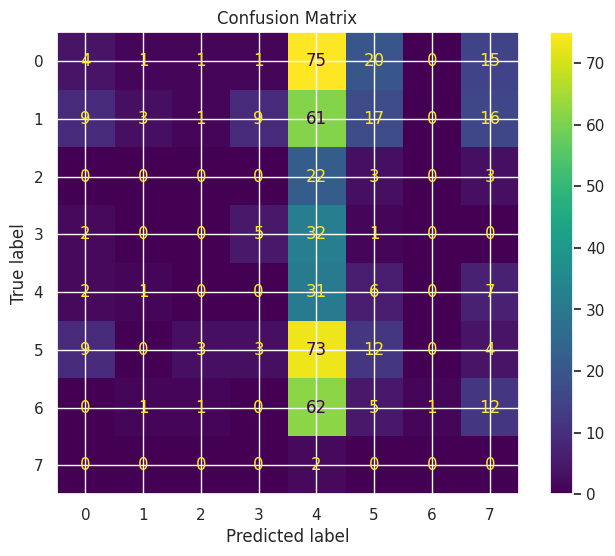


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: CNN_dropout_1e-1.8
------------------------------
TRAIN
Accuracy: 0.5596
Precision: 0.6142
Recall: 0.5596
F1: 0.5491
Kappa: 0.4534
Error Rate: 0.4404

TEST
Accuracy: 0.1082
Precision: 0.3959
Recall: 0.1082
F1: 0.0715
Kappa: 0.0015
Error Rate: 0.8918
Gap (overfitting): 0.4514

CV
Mean: 0.5602
Std: 0.0611
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



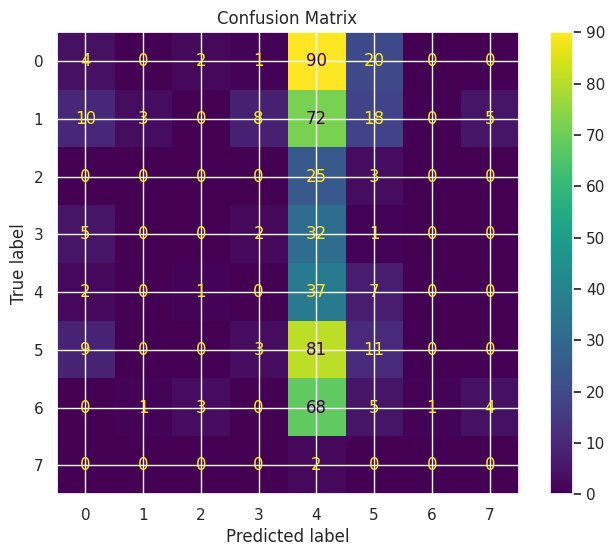

In [17]:
models_cnn_f2 = {}

# ============================================================
# OTIMIZADORES (3 solvers)
# ============================================================

models_cnn_f2['CNN_solver_adam'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f2['CNN_solver_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f2['CNN_solver_rmsprop'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# ARQUITETURAS (diferentes números de filtros)
# ============================================================

# equivalente a hidden=30
models_cnn_f2['CNN_arch_30'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

# equivalente a hidden=50
models_cnn_f2['CNN_arch_50'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

# equivalente a 50_25 (2 camadas convolucionais + FC)
models_cnn_f2['CNN_arch_50_25'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# REGULARIZAÇÃO (dropout)
# ============================================================

models_cnn_f2['CNN_dropout_0'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f2['CNN_dropout_1e-1'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.1, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f2['CNN_dropout_1e-1.5'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f2['CNN_dropout_1e-1.8'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.3, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_cnn_f2, "cnn_fase_2")

/tmp/ipykernel_479/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd
------------------------------
TRAIN
Accuracy: 0.7718
Precision: 0.7890
Recall: 0.7718
F1: 0.7662
Kappa: 0.7218
Error Rate: 0.2282

TEST
Accuracy: 0.2649
Precision: 0.1842
Recall: 0.2649
F1: 0.1670
Kappa: 0.0646
Error Rate: 0.7351
Gap (overfitting): 0.5069

CV
Mean: 0.7389
Std: 0.1003
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



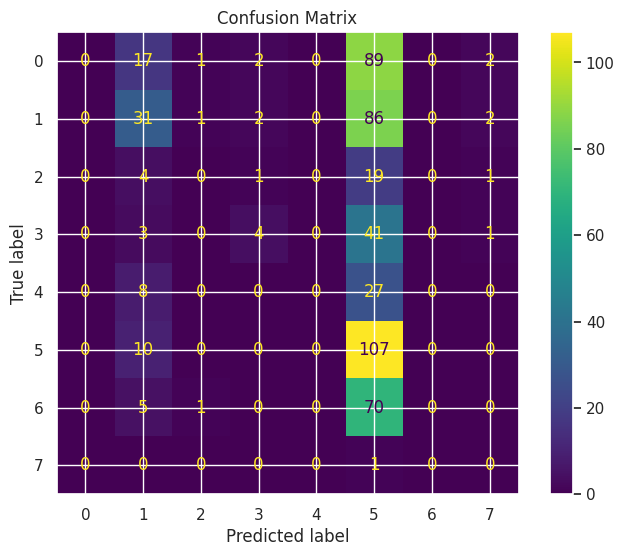

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_momentum95
------------------------------
TRAIN
Accuracy: 0.8022
Precision: 0.8157
Recall: 0.8022
F1: 0.7986
Kappa: 0.7594
Error Rate: 0.1978

TEST
Accuracy: 0.2780
Precision: 0.3983
Recall: 0.2780
F1: 0.1778
Kappa: 0.0819
Error Rate: 0.7220
Gap (overfitting): 0.5243

CV
Mean: 0.7569
Std: 0.0971
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



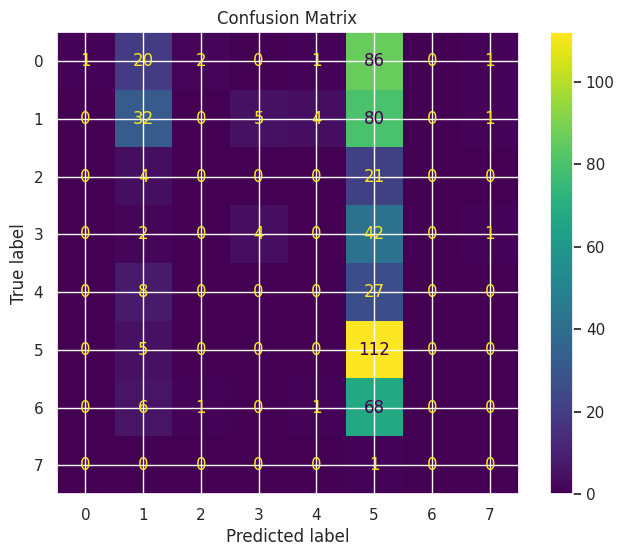

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd
------------------------------
TRAIN
Accuracy: 0.8215
Precision: 0.8281
Recall: 0.8215
F1: 0.8191
Kappa: 0.7829
Error Rate: 0.1785

TEST
Accuracy: 0.2388
Precision: 0.1926
Recall: 0.2388
F1: 0.1569
Kappa: 0.0597
Error Rate: 0.7612
Gap (overfitting): 0.5827

CV
Mean: 0.7675
Std: 0.1079
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



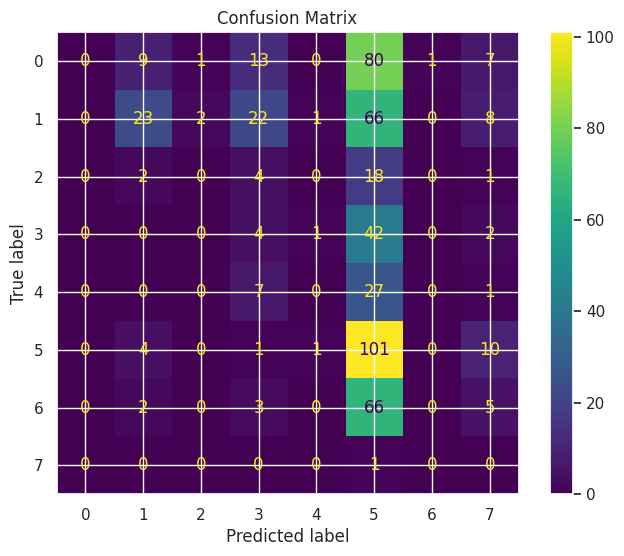

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd_momentum95
------------------------------
TRAIN
Accuracy: 0.8543
Precision: 0.8604
Recall: 0.8543
F1: 0.8527
Kappa: 0.8231
Error Rate: 0.1457

TEST
Accuracy: 0.2481
Precision: 0.2061
Recall: 0.2481
F1: 0.1762
Kappa: 0.0748
Error Rate: 0.7519
Gap (overfitting): 0.6061

CV
Mean: 0.7681
Std: 0.1045
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



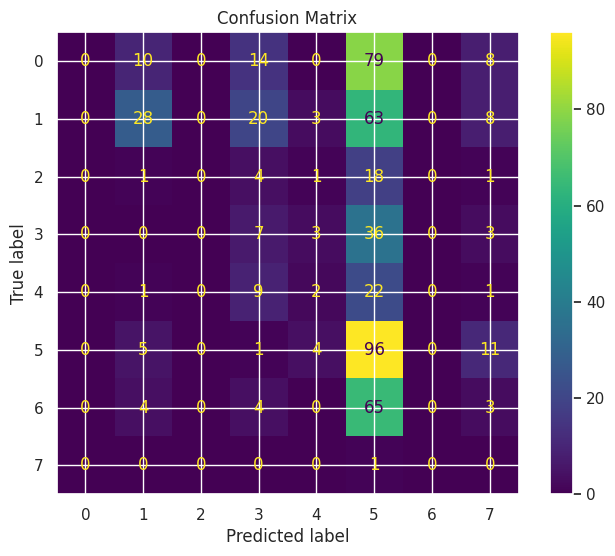

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_sgd
------------------------------
TRAIN
Accuracy: 0.9416
Precision: 0.9442
Recall: 0.9416
F1: 0.9415
Kappa: 0.9293
Error Rate: 0.0584

TEST
Accuracy: 0.2295
Precision: 0.1875
Recall: 0.2295
F1: 0.1195
Kappa: 0.0200
Error Rate: 0.7705
Gap (overfitting): 0.7121

CV
Mean: 0.8611
Std: 0.0944
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



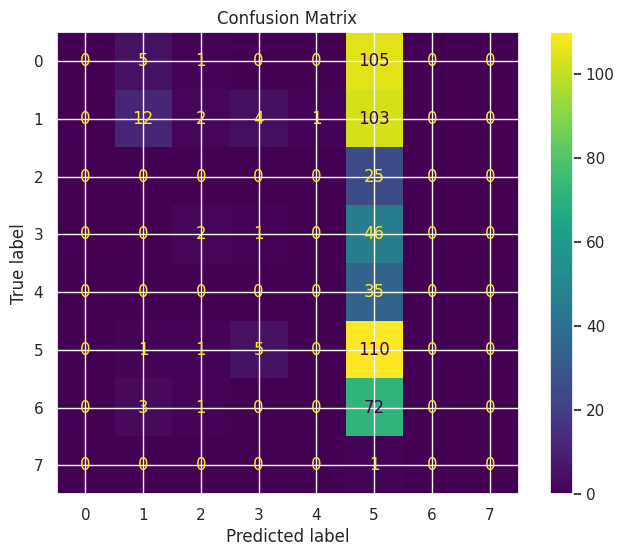

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_sgd_momentum95
------------------------------
TRAIN
Accuracy: 0.8855
Precision: 0.8919
Recall: 0.8855
F1: 0.8861
Kappa: 0.8626
Error Rate: 0.1145

TEST
Accuracy: 0.2108
Precision: 0.1747
Recall: 0.2108
F1: 0.1295
Kappa: 0.0076
Error Rate: 0.7892
Gap (overfitting): 0.6747

CV
Mean: 0.8594
Std: 0.1061
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



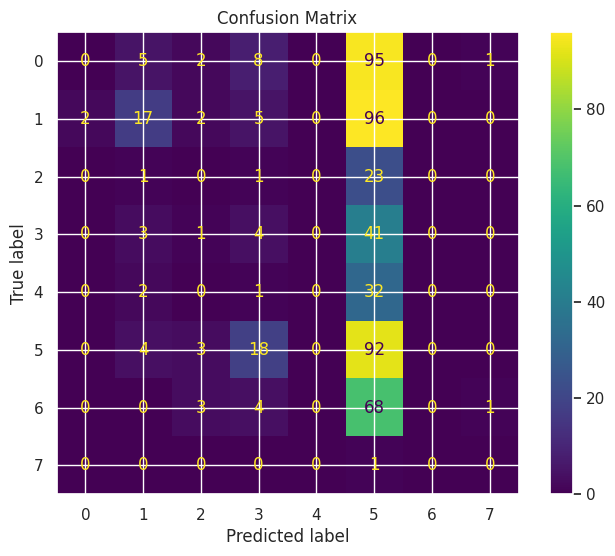


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_adam_reg1e-4
------------------------------
TRAIN
Accuracy: 0.5845
Precision: 0.6315
Recall: 0.5845
F1: 0.5813
Kappa: 0.4889
Error Rate: 0.4155

TEST
Accuracy: 0.1269
Precision: 0.5244
Recall: 0.1269
F1: 0.1162
Kappa: 0.0510
Error Rate: 0.8731
Gap (overfitting): 0.4576

CV
Mean: 0.5810
Std: 0.0344
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



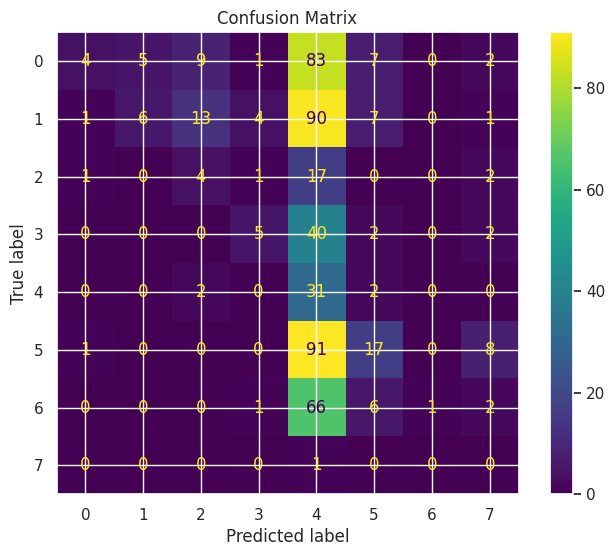

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_adam_reg1e-4
------------------------------
TRAIN
Accuracy: 0.6325
Precision: 0.6580
Recall: 0.6325
F1: 0.6327
Kappa: 0.5493
Error Rate: 0.3675

TEST
Accuracy: 0.1418
Precision: 0.3495
Recall: 0.1418
F1: 0.1309
Kappa: 0.0571
Error Rate: 0.8582
Gap (overfitting): 0.4907

CV
Mean: 0.6275
Std: 0.0365
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



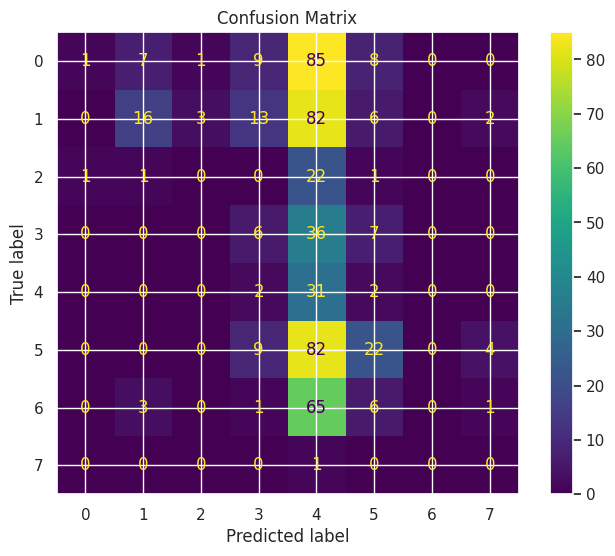

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_adam_reg1e-4
------------------------------
TRAIN
Accuracy: 0.5693
Precision: 0.6065
Recall: 0.5693
F1: 0.5475
Kappa: 0.4681
Error Rate: 0.4307

TEST
Accuracy: 0.1007
Precision: 0.3859
Recall: 0.1007
F1: 0.0698
Kappa: 0.0149
Error Rate: 0.8993
Gap (overfitting): 0.4685

CV
Mean: 0.5994
Std: 0.0168
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.2, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



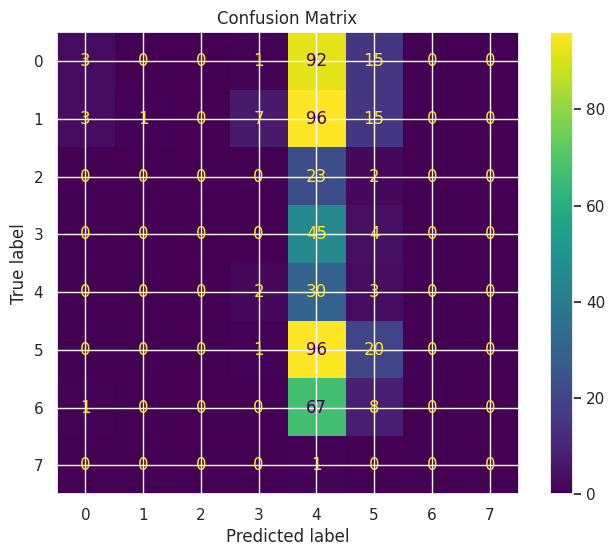

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_dropout2
------------------------------
TRAIN
Accuracy: 0.7302
Precision: 0.7599
Recall: 0.7302
F1: 0.7287
Kappa: 0.6688
Error Rate: 0.2698

TEST
Accuracy: 0.1530
Precision: 0.2134
Recall: 0.1530
F1: 0.1123
Kappa: 0.0269
Error Rate: 0.8470
Gap (overfitting): 0.5772

CV
Mean: 0.6577
Std: 0.0503
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



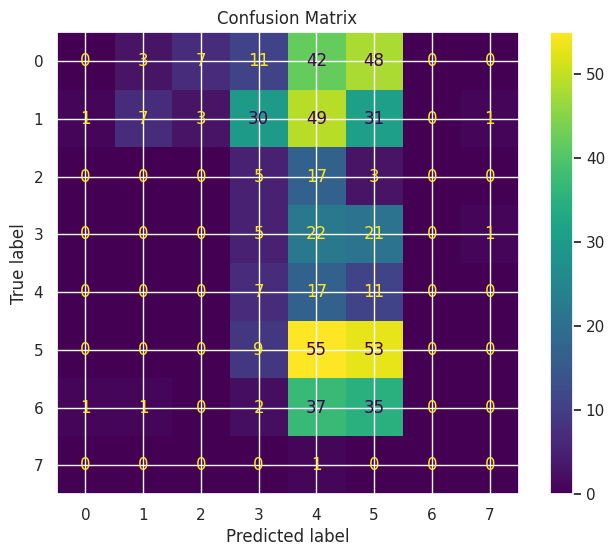

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_dropout3
------------------------------
TRAIN
Accuracy: 0.6926
Precision: 0.7288
Recall: 0.6926
F1: 0.6897
Kappa: 0.6226
Error Rate: 0.3074

TEST
Accuracy: 0.1362
Precision: 0.3171
Recall: 0.1362
F1: 0.1110
Kappa: 0.0433
Error Rate: 0.8638
Gap (overfitting): 0.5564

CV
Mean: 0.6347
Std: 0.0303
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



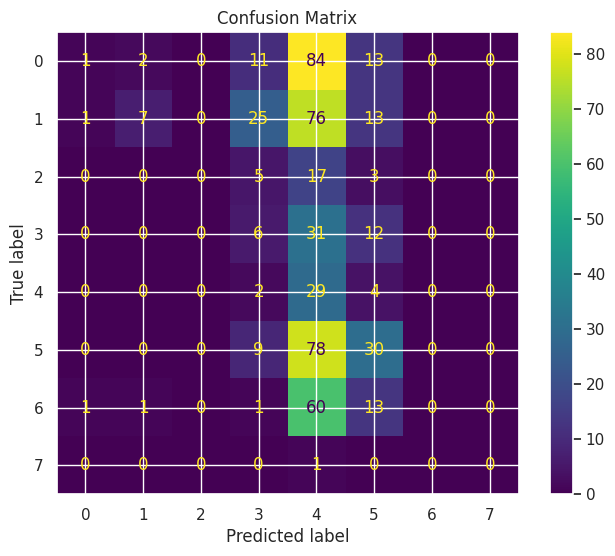

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_lowLR
------------------------------
TRAIN
Accuracy: 0.5981
Precision: 0.6162
Recall: 0.5981
F1: 0.5909
Kappa: 0.5061
Error Rate: 0.4019

TEST
Accuracy: 0.1530
Precision: 0.2704
Recall: 0.1530
F1: 0.1467
Kappa: 0.0700
Error Rate: 0.8470
Gap (overfitting): 0.4451

CV
Mean: 0.5810
Std: 0.0279
------------------------------
Model params:
{'num_filters': [16], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



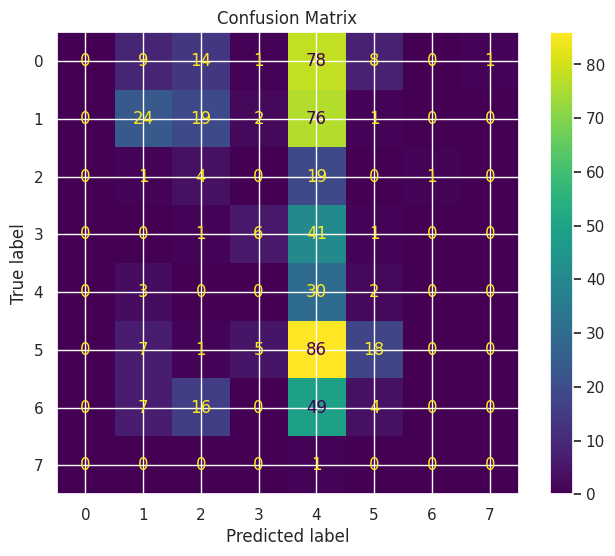

In [18]:
models_cnn_f3 = {}

# ============================================================
# 🔥 BASE TOP (SGD)
# Variações de filtros e momentum
# ============================================================

models_cnn_f3['F2_30_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_30_sgd_momentum95'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_50_sgd'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_50_sgd_momentum95'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_50_25_sgd'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_50_25_sgd_momentum95'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================

models_cnn_f3['F2_30_adam_reg1e-4'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_50_adam_reg1e-4'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_50_25_adam_reg1e-4'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.2, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================

models_cnn_f3['F2_30_sgd_dropout2'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_30_sgd_dropout3'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f3['F2_30_sgd_lowLR'] = CNN1DClassifier(
    num_filters=[16], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

main(models_cnn_f3, "cnn_fase_3")

/tmp/ipykernel_479/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_dropout0_sgd
------------------------------
TRAIN
Accuracy: 0.8127
Precision: 0.8195
Recall: 0.8127
F1: 0.8121
Kappa: 0.7723
Error Rate: 0.1873

TEST
Accuracy: 0.0933
Precision: 0.1362
Recall: 0.0933
F1: 0.0711
Kappa: 0.0329
Error Rate: 0.9067
Gap (overfitting): 0.7194

CV
Mean: 0.7406
Std: 0.0807
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



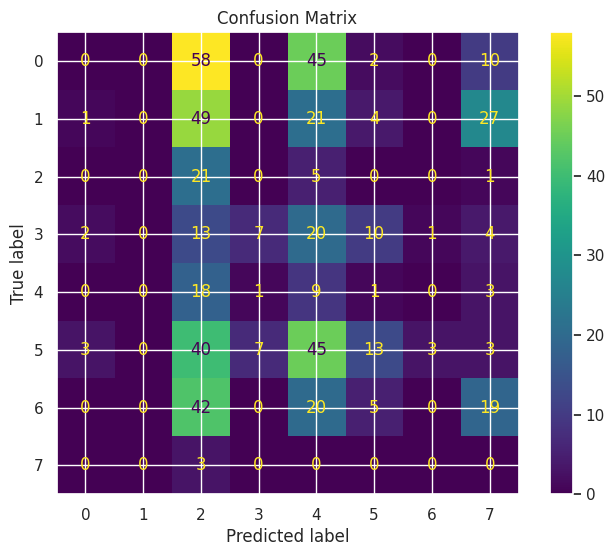

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr5e-4_dropout0_sgd
------------------------------
TRAIN
Accuracy: 0.7510
Precision: 0.7613
Recall: 0.7510
F1: 0.7489
Kappa: 0.6959
Error Rate: 0.2490

TEST
Accuracy: 0.1045
Precision: 0.1408
Recall: 0.1045
F1: 0.0770
Kappa: 0.0376
Error Rate: 0.8955
Gap (overfitting): 0.6465

CV
Mean: 0.6812
Std: 0.0557
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



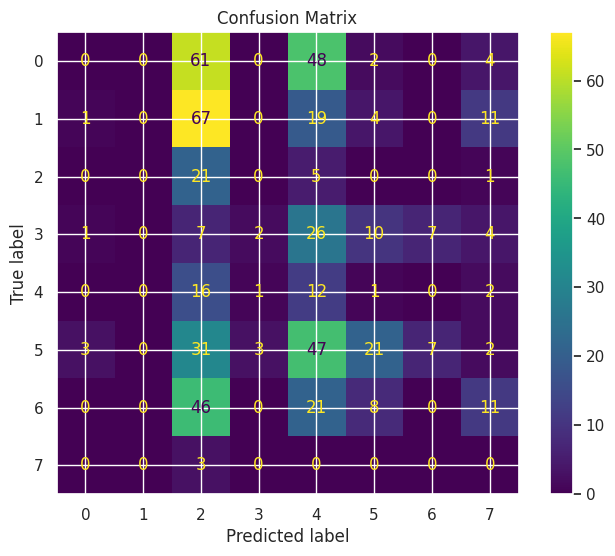

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-4_dropout0_sgd
------------------------------
TRAIN
Accuracy: 0.5845
Precision: 0.6061
Recall: 0.5845
F1: 0.5668
Kappa: 0.4859
Error Rate: 0.4155

TEST
Accuracy: 0.1604
Precision: 0.1179
Recall: 0.1604
F1: 0.1210
Kappa: 0.0591
Error Rate: 0.8396
Gap (overfitting): 0.4240

CV
Mean: 0.5389
Std: 0.0176
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.0, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



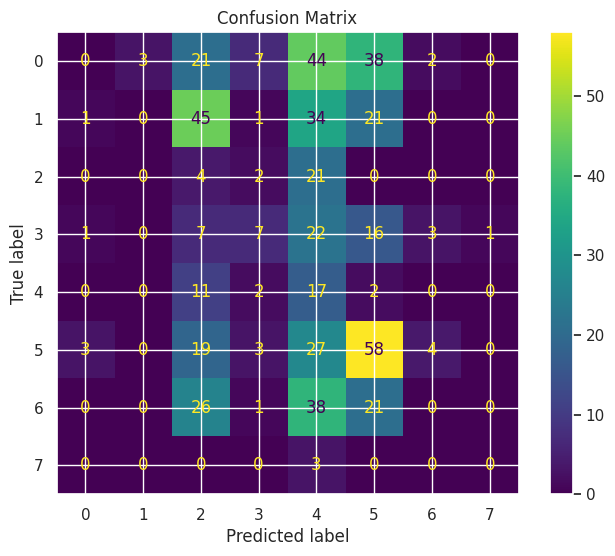

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_dropout1_sgd
------------------------------
TRAIN
Accuracy: 0.7070
Precision: 0.7263
Recall: 0.7070
F1: 0.7044
Kappa: 0.6416
Error Rate: 0.2930

TEST
Accuracy: 0.0728
Precision: 0.0945
Recall: 0.0728
F1: 0.0340
Kappa: 0.0080
Error Rate: 0.9272
Gap (overfitting): 0.6342

CV
Mean: 0.6459
Std: 0.0579
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.1, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



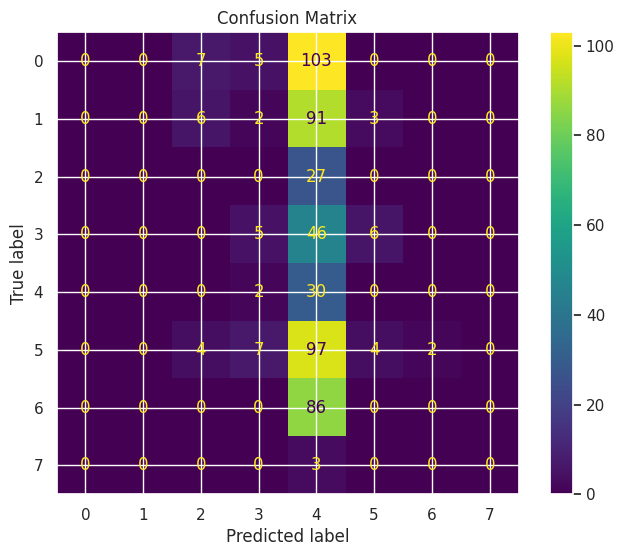

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_dropout2_sgd
------------------------------
TRAIN
Accuracy: 0.6693
Precision: 0.6998
Recall: 0.6693
F1: 0.6684
Kappa: 0.5951
Error Rate: 0.3307

TEST
Accuracy: 0.0653
Precision: 0.2537
Recall: 0.0653
F1: 0.0174
Kappa: 0.0054
Error Rate: 0.9347
Gap (overfitting): 0.6040

CV
Mean: 0.6168
Std: 0.0481
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



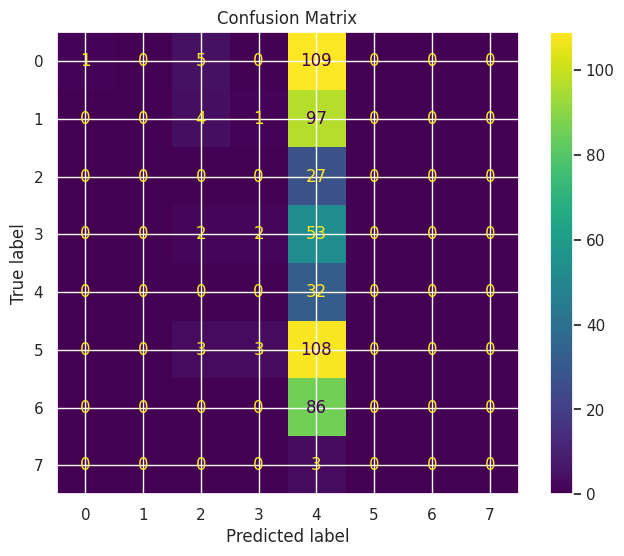

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3_dropout3_sgd
------------------------------
TRAIN
Accuracy: 0.6413
Precision: 0.6705
Recall: 0.6413
F1: 0.6389
Kappa: 0.5601
Error Rate: 0.3587

TEST
Accuracy: 0.0634
Precision: 0.2537
Recall: 0.0634
F1: 0.0141
Kappa: 0.0036
Error Rate: 0.9366
Gap (overfitting): 0.5779

CV
Mean: 0.5905
Std: 0.0259
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.3, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



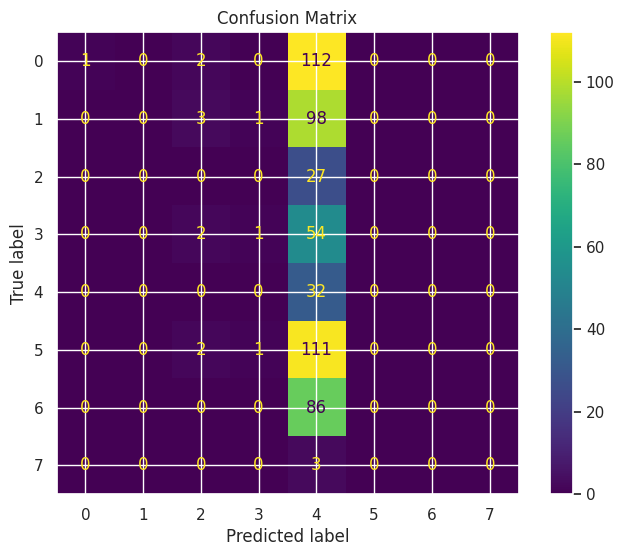

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr5e-4_dropout2_sgd
------------------------------
TRAIN
Accuracy: 0.6517
Precision: 0.6862
Recall: 0.6517
F1: 0.6503
Kappa: 0.5720
Error Rate: 0.3483

TEST
Accuracy: 0.0653
Precision: 0.2449
Recall: 0.0653
F1: 0.0173
Kappa: 0.0052
Error Rate: 0.9347
Gap (overfitting): 0.5864

CV
Mean: 0.5994
Std: 0.0394
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



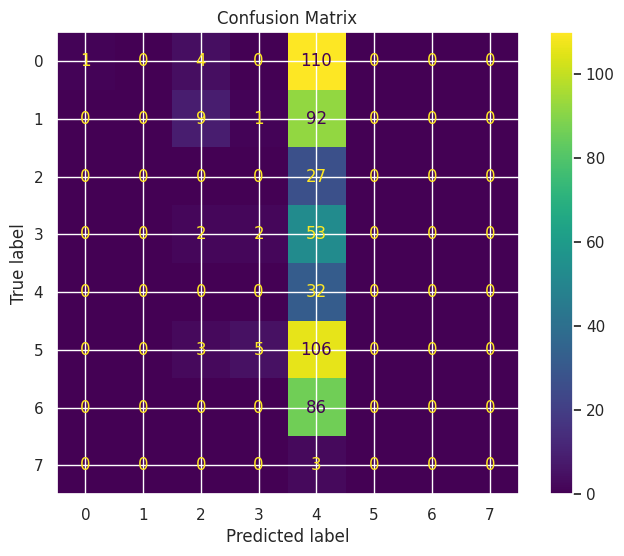

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr1e-3_dropout0_sgd
------------------------------
TRAIN
Accuracy: 0.9760
Precision: 0.9763
Recall: 0.9760
F1: 0.9758
Kappa: 0.9709
Error Rate: 0.0240

TEST
Accuracy: 0.1698
Precision: 0.1334
Recall: 0.1698
F1: 0.0932
Kappa: -0.0215
Error Rate: 0.8302
Gap (overfitting): 0.8062

CV
Mean: 0.8622
Std: 0.1093
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



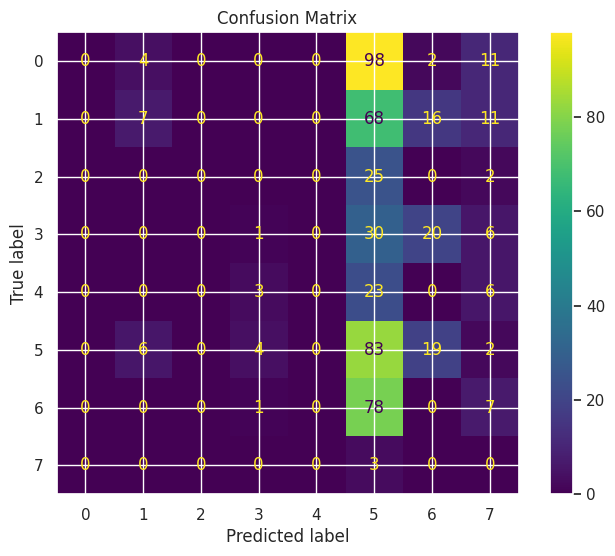

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr5e-4_dropout0_sgd
------------------------------
TRAIN
Accuracy: 0.9095
Precision: 0.9146
Recall: 0.9095
F1: 0.9092
Kappa: 0.8907
Error Rate: 0.0905

TEST
Accuracy: 0.1549
Precision: 0.0607
Recall: 0.1549
F1: 0.0709
Kappa: -0.0366
Error Rate: 0.8451
Gap (overfitting): 0.7547

CV
Mean: 0.8543
Std: 0.1237
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



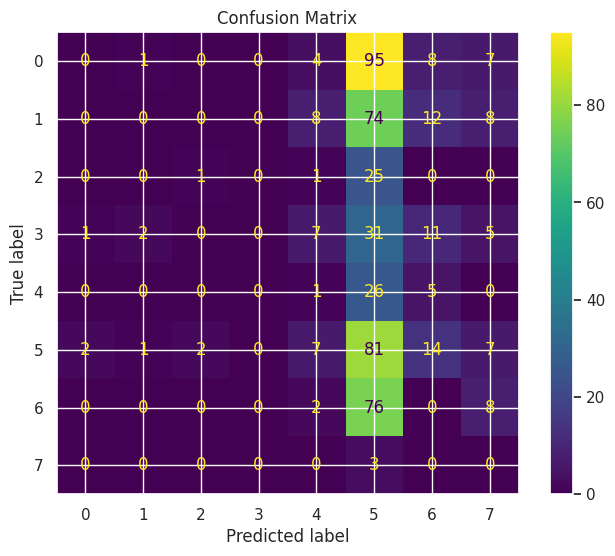

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr1e-4_dropout0_sgd
------------------------------
TRAIN
Accuracy: 0.7198
Precision: 0.7114
Recall: 0.7198
F1: 0.7054
Kappa: 0.6554
Error Rate: 0.2802

TEST
Accuracy: 0.1866
Precision: 0.1340
Recall: 0.1866
F1: 0.1037
Kappa: -0.0097
Error Rate: 0.8134
Gap (overfitting): 0.5332

CV
Mean: 0.6756
Std: 0.0672
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.0, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



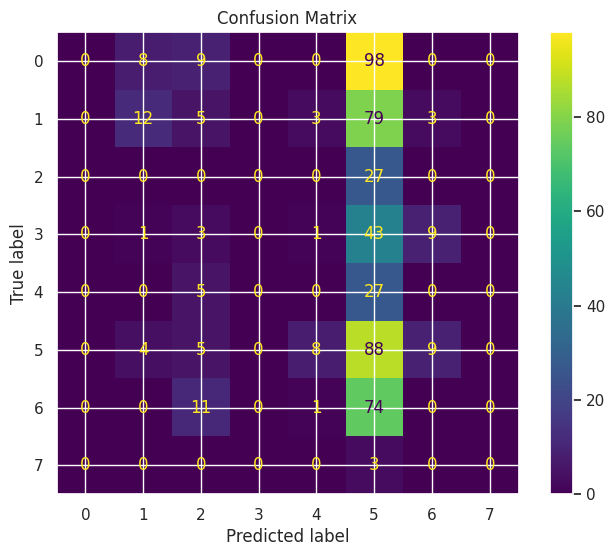

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr1e-3_dropout2_sgd
------------------------------
TRAIN
Accuracy: 0.7270
Precision: 0.7651
Recall: 0.7270
F1: 0.7234
Kappa: 0.6643
Error Rate: 0.2730

TEST
Accuracy: 0.0541
Precision: 0.0650
Recall: 0.0541
F1: 0.0375
Kappa: -0.0453
Error Rate: 0.9459
Gap (overfitting): 0.6729

CV
Mean: 0.6728
Std: 0.0285
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.2, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



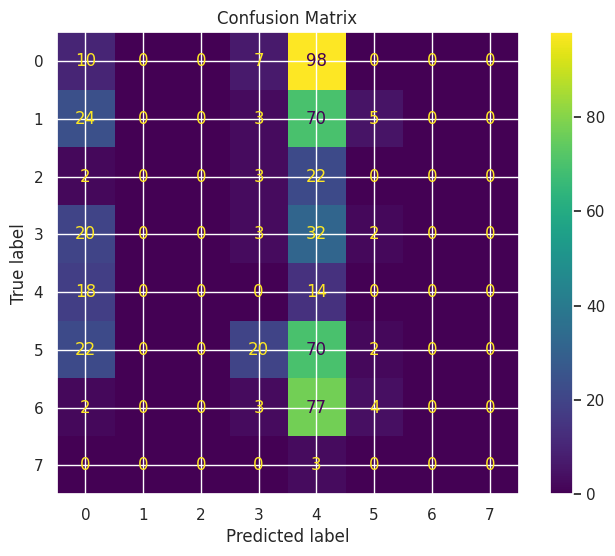

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-4_dropout2_adam
------------------------------
TRAIN
Accuracy: 0.5805
Precision: 0.6226
Recall: 0.5805
F1: 0.5740
Kappa: 0.4824
Error Rate: 0.4195

TEST
Accuracy: 0.0653
Precision: 0.2449
Recall: 0.0653
F1: 0.0201
Kappa: 0.0039
Error Rate: 0.9347
Gap (overfitting): 0.5152

CV
Mean: 0.5608
Std: 0.0361
------------------------------
Model params:
{'num_filters': [8], 'kernel_sizes': [3], 'dropout': 0.2, 'fc_hidden_layers': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



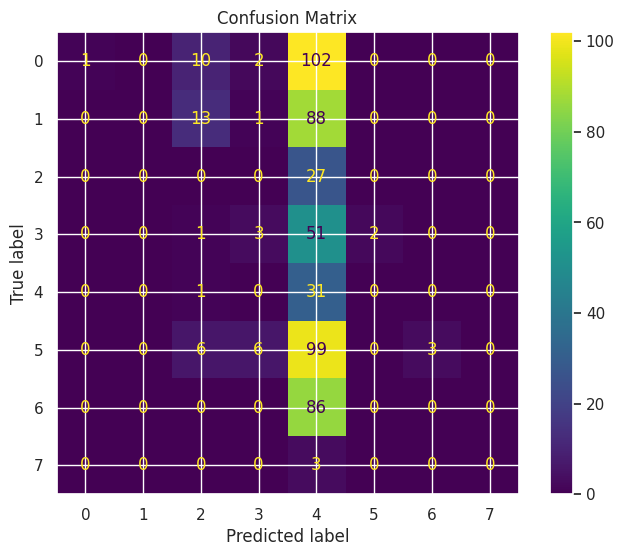

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr1e-4_dropout2_adam
------------------------------
TRAIN
Accuracy: 0.5612
Precision: 0.5556
Recall: 0.5612
F1: 0.5316
Kappa: 0.4577
Error Rate: 0.4388

TEST
Accuracy: 0.0765
Precision: 0.0134
Recall: 0.0765
F1: 0.0228
Kappa: -0.0122
Error Rate: 0.9235
Gap (overfitting): 0.4848

CV
Mean: 0.5664
Std: 0.0214
------------------------------
Model params:
{'num_filters': [16, 8], 'kernel_sizes': [3, 3], 'dropout': 0.2, 'fc_hidden_layers': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



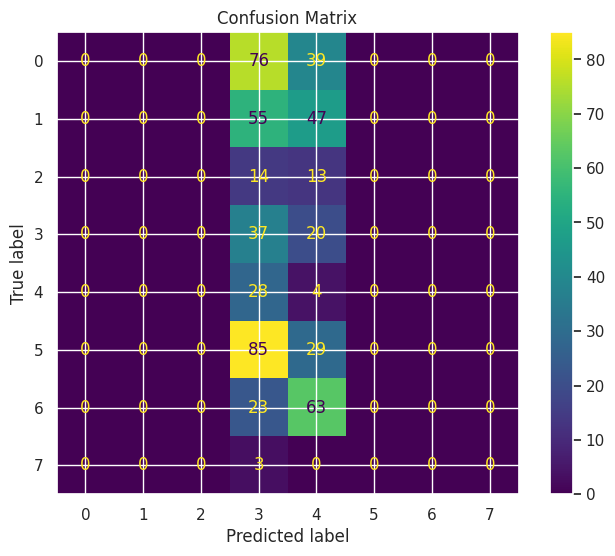

In [19]:
models_cnn_f4 = {}

# ============================================================
# 🔥 SGD com num_filters=30 (base)
# Variações de learning rate e dropout
# ============================================================

models_cnn_f4['F3_30_lr1e-3_dropout0_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_30_lr5e-4_dropout0_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_30_lr1e-4_dropout0_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.0, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_30_lr1e-3_dropout1_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.1, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_30_lr1e-3_dropout2_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_30_lr1e-3_dropout3_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.3, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_30_lr5e-4_dropout2_sgd'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 🔥 SGD com num_filters=50_25 (2 camadas convolucionais)
# ============================================================

models_cnn_f4['F3_50_25_lr1e-3_dropout0_sgd'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_50_25_lr5e-4_dropout0_sgd'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_50_25_lr1e-4_dropout0_sgd'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.0, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_50_25_lr1e-3_dropout2_sgd'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.2, fc_hidden_layers=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================

models_cnn_f4['F3_30_lr1e-4_dropout2_adam'] = CNN1DClassifier(
    num_filters=[8], kernel_sizes=[3], dropout=0.2, fc_hidden_layers=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_cnn_f4['F3_50_25_lr1e-4_dropout2_adam'] = CNN1DClassifier(
    num_filters=[16, 8], kernel_sizes=[3, 3], dropout=0.2, fc_hidden_layers=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_cnn_f4, "cnn_fase_4")